In [1]:
# Importing Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from warnings import filterwarnings
filterwarnings('ignore')

In [2]:
# importing dataset

df=pd.read_csv('DataCoSupplyChainDataset.csv',encoding='latin-1')

In [3]:
# setting colorpallette

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')

viridis_colors=cm.viridis(np.linspace(0,1,5))
primary_color=viridis_colors[0]
secondary_color=viridis_colors[1]
accent_color=viridis_colors[2]
neutral_color=viridis_colors[4]
custom_color=viridis_colors
danger_color='#800000'

In [4]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

In [5]:
# Dropping unnessary coloumns

df.drop(columns=['Benefit per order','Sales per customer','Customer City','Customer Country','Customer Fname','Customer Id','Customer Lname','Customer Password','Customer State','Customer Street','Customer Zipcode','Department Id','Latitude','Longitude','Market',
                  'Order City','Order Country','Order Customer Id','Order Id','Order Item Cardprod Id','Order Item Discount','Order Item Discount Rate','Order Item Id',
                  'Order Item Profit Ratio','Product Card Id','Product Category Id','Product Image','Customer Email','Category Id','Order Item Product Price', 'Order Item Quantity','Sales','Order Item Total','Order Zipcode','Product Description','Product Status'
            
                 ],inplace=True)

In [6]:
# Details of table

print('rows,cols:',df.shape)
print('\ncolumns:')
print(df.columns.tolist())
print('\nNum Duplicates:',df.duplicated().sum())
print('\nNum Missing:',)
print(df.isna().sum().sort_values(ascending=False).head(5))

rows,cols: (180519, 17)

columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Delivery Status', 'Late_delivery_risk', 'Category Name', 'Customer Segment', 'Department Name', 'order date (DateOrders)', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Product Price', 'shipping date (DateOrders)', 'Shipping Mode']

Num Duplicates: 18

Num Missing:
Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Delivery Status                  0
Late_delivery_risk               0
dtype: int64


In [7]:
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Late_delivery_risk,Order Profit Per Order,Product Price
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000
mean,3.497654,2.931847,0.548291,21.974989,141.232550
std,1.623722,1.374449,0.497664,104.433526,139.732492
min,0.000000,0.000000,0.000000,-4274.979980,9.990000
25%,2.000000,2.000000,0.000000,7.000000,50.000000
50%,3.000000,4.000000,1.000000,31.520000,59.990002
75%,5.000000,4.000000,1.000000,64.800003,199.990005
max,6.000000,4.000000,1.000000,911.799988,1999.989990


In [ ]:
for col in df.columns:
    if df[col].nunique()<10:
     print(df[col].value_counts())

Type
DEBIT       69295
TRANSFER    49883
PAYMENT     41725
CASH        19616
Name: count, dtype: int64
Days for shipping (real)
2    56618
3    28765
6    28723
4    28513
5    28163
0     5080
1     4657
Name: count, dtype: int64
Days for shipment (scheduled)
4    107752
2     35216
1     27814
0      9737
Name: count, dtype: int64
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64
Customer Segment
Consumer       93504
Corporate      54789
Home Office    32226
Name: count, dtype: int64
Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64
Shipping Mode
Standard Class    107752
Second Class       35216
First Class   

In [9]:
df['order date (DateOrders)']=pd.to_datetime(df['order date (DateOrders)'])
df['shipping date (DateOrders)']=pd.to_datetime(df['shipping date (DateOrders)'])

In [10]:
#Feature Engineering

df['Order Processing Time']=(df['shipping date (DateOrders)'] - df['order date (DateOrders)']).dt.days
df['Delays']=(df['Days for shipping (real)'] - df['Days for shipment (scheduled)'])
df['is_delayed']=df['Delays']>0
df['order_month']=df['order date (DateOrders)'].dt.month
df['order_day']=df['order date (DateOrders)'].dt.day_name()
df['order_hour']=df['order date (DateOrders)'].dt.hour
df['profitability_flag']=np.where(df['Order Profit Per Order']>0,'Profit',np.where(df['Order Profit Per Order']<0,'Loss','Break-even'))

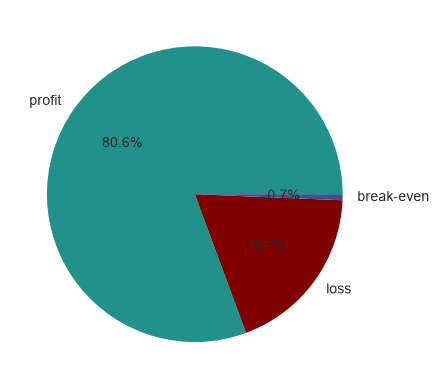

In [21]:
profit_count=df['profitability_flag'].value_counts(normalize=True)*100
plt.pie(profit_count,autopct='%0.1f%%',labels=['profit','loss','break-even'],colors=[accent_color,danger_color,secondary_color])

In [13]:
# KPI's

def format_func(value):
    if value >=1e6:
        return f'{value/1e6:.1f}M $'
    elif value >=1e3:
        return f'{value/1e3:.1f}k $'
    else:
        return f'{value:.0f} $'

delayed_df=df[df['Delays']>0]

metrices={}
metrices['Total Orders']= len(df)
metrices['Late Deliveries']=len(df[df['is_delayed']==True])
metrices['90% Delay (days)']=delayed_df['Delays'].quantile(0.90)
metrices['On-time delivery %']=len(df[df['is_delayed']==False])/len(df['is_delayed'])*100
metrices['Late delivery %']= 100-len(df[df['is_delayed']==False])/len(df['is_delayed'])*100
metrices['Total Profit']=format_func(df.loc[df['Order Profit Per Order']>0,'Order Profit Per Order'].sum())
metrices['Loss due to delays']=format_func(df.loc[df['Delays']>0,'Order Profit Per Order'].sum())

print("\n--------Business KPI's---------\n")

for k,v in metrices.items():
    if isinstance(v,float):
        print(f'{k}:{v:.2f}')
    else:
        print(f'{k}:{v}')


--------Business KPI's---------

Total Orders:180519
Late Deliveries:103400
90% Delay (days):3.00
On-time delivery %:42.72
Late delivery %:57.28
Total Profit:7.9M $
Loss due to delays:2.2M $


In [14]:
# Profitability vs Delivery Time Analysis

In [15]:
Profit_Matrics=(
    df.groupby('Delays')['Order Profit Per Order'].agg(mean_profit='mean',total_profit='sum',order_count='count').reset_index()
)
Profit_Matrics

,Delays,mean_profit,total_profit,order_count
0,-2,23.423528,5.074942e+05,21666
1,-1,21.516997,4.669188e+05,21700
2,0,22.532021,7.605233e+05,33753
3,1,21.940582,1.330630e+06,60647
4,2,21.246239,6.101495e+05,28718
5,3,19.941130,1.406248e+05,7052
6,4,21.561202,1.505619e+05,6983


In [16]:
Delay_Distribution=(
    df['Delays'].value_counts(normalize=True).sort_index()*100
).reset_index()
Delay_Distribution.columns=['Delay_days','Percentage']
Delay_Distribution

,Delay_days,Percentage
0,-2,12.002061
1,-1,12.020895
2,0,18.697755
3,1,33.595910
4,2,15.908575
5,3,3.906514
6,4,3.868291



Profit metrics by delay_days:


,Delays,mean_profit,total_profit,order_count
0,-2,23.4,507494.2,21666
1,-1,21.5,466918.8,21700
2,0,22.5,760523.3,33753
3,1,21.9,1330630.5,60647
4,2,21.2,610149.5,28718
5,3,19.9,140624.8,7052
6,4,21.6,150561.9,6983



Delay Distribution (%)


,Delay_days,Percentage
0,-2,12.00
1,-1,12.02
2,0,18.70
3,1,33.60
4,2,15.91
5,3,3.91
6,4,3.87


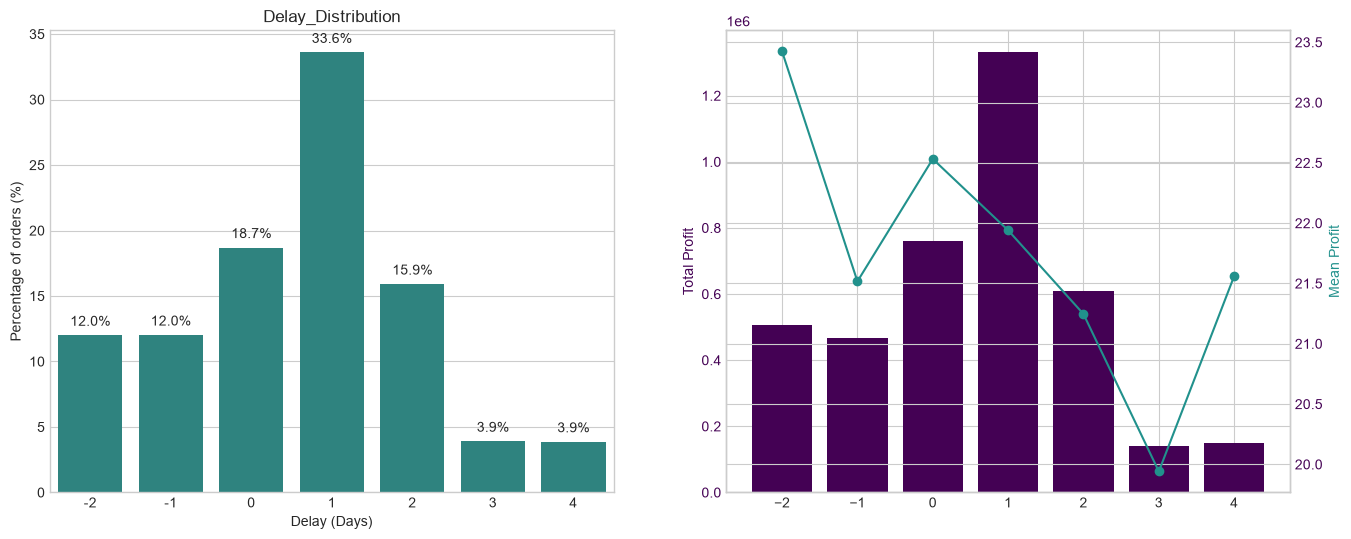

In [17]:
print('\nProfit metrics by delay_days:')
display(Profit_Matrics.round(1))

print('\nDelay Distribution (%)')
display(Delay_Distribution.round(2))

fig,(ax1,ax2)=plt.subplots(1,2,figsize=(16,6))

#First SubPlot: Delay Distribution
sns.barplot(x='Delay_days',y='Percentage',data=Delay_Distribution,ax=ax1,color=accent_color)
ax1.set_title('Delay_Distribution')
ax1.set_xlabel("Delay (Days)")
ax1.set_ylabel('Percentage of orders (%)')

# Percentage text on bars
for bar in ax1.patches:
    height=bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height + 0.5, f'{height:.1f}%',ha='center',va='bottom')

# Second Subplot: Profit Analysis by delay days

ax2.set_ylabel('Total Profit',color=primary_color)
ax2.bar(Profit_Matrics['Delays'],Profit_Matrics['total_profit'],label='Total Profit',color=primary_color)
ax2.tick_params(axis='y',labelcolor=primary_color)

ax3=ax2.twinx()

ax3.set_xlabel('Delay_days')
ax3.set_ylabel('Mean Profit',color=accent_color)
ax3.plot(Profit_Matrics['Delays'],Profit_Matrics['mean_profit'],marker='o',label='Mean Profit',color=accent_color)
ax3.tick_params(axis='y',labelcolor=primary_color)


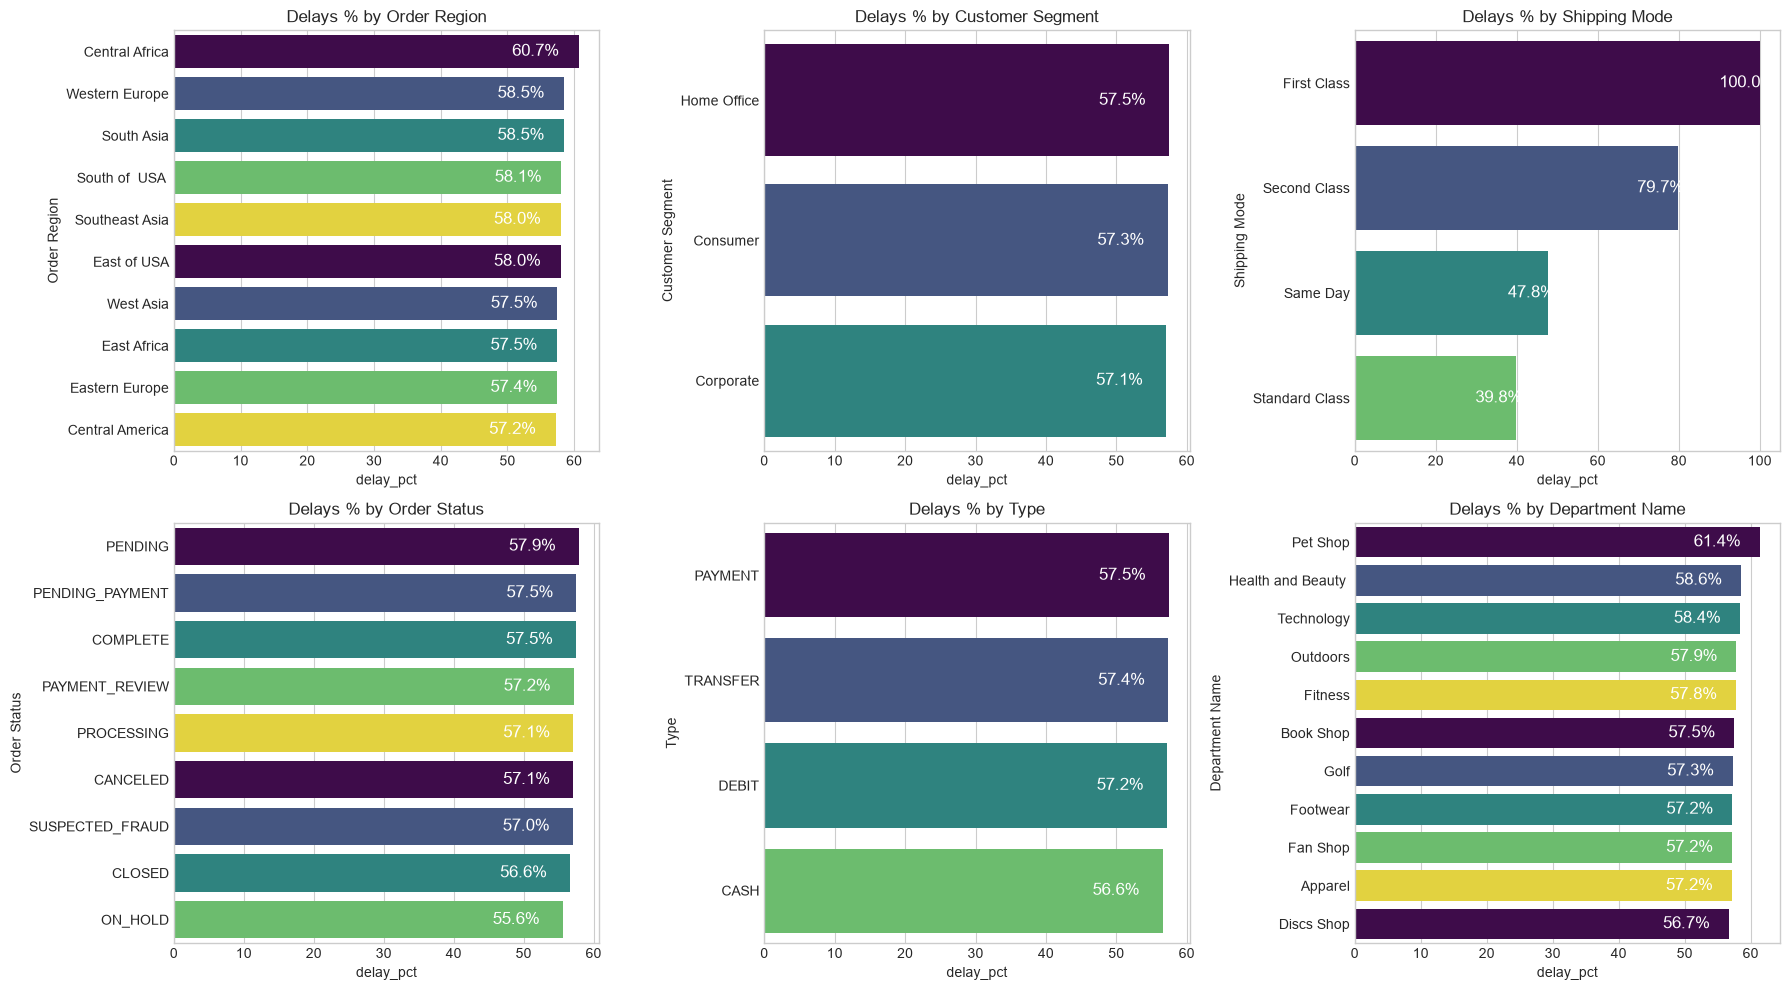

In [18]:
# Bottleneck detections

# 1) Order Region
region_delay = df.groupby('Order Region').agg(
    total_orders=('Delays', 'count'),
    late_orders=('is_delayed', 'sum')
)
region_delay['delay_pct'] = region_delay['late_orders'] / region_delay['total_orders'] * 100
region_delay = region_delay.sort_values('delay_pct', ascending=False).head(10)

# 2) Customer Segment
segment_delay = df.groupby('Customer Segment').agg(
    total_orders=('Delays', 'count'),
    late_orders=('is_delayed', 'sum')
)
segment_delay['delay_pct'] = segment_delay['late_orders'] / segment_delay['total_orders'] * 100
segment_delay = segment_delay.sort_values('delay_pct', ascending=False)

# 3) Shipping Mode
shipping_delay = df.groupby('Shipping Mode').agg(
    total_orders=('Delays', 'count'),
    late_orders=('is_delayed', 'sum')
)
shipping_delay['delay_pct'] = shipping_delay['late_orders'] / shipping_delay['total_orders'] * 100
shipping_delay = shipping_delay.sort_values('delay_pct', ascending=False)

# 4) Order Status
status_delay = df.groupby('Order Status').agg(
    total_orders=('Delays', 'count'),
    late_orders=('is_delayed', 'sum')
)
status_delay['delay_pct'] = status_delay['late_orders'] / status_delay['total_orders'] * 100
status_delay = status_delay.sort_values('delay_pct', ascending=False)

# 5) Type
type_delay = df.groupby('Type').agg(
    total_orders=('Delays', 'count'),
    late_orders=('is_delayed', 'sum')
)
type_delay['delay_pct'] = type_delay['late_orders'] / type_delay['total_orders'] * 100
type_delay = type_delay.sort_values('delay_pct', ascending=False)

# 6) Department Name
dept_delay = df.groupby('Department Name').agg(
    total_orders=('Delays', 'count'),
    late_orders=('is_delayed', 'sum')
)
dept_delay['delay_pct'] = dept_delay['late_orders'] / dept_delay['total_orders'] * 100
dept_delay = dept_delay.sort_values('delay_pct', ascending=False)


fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.barplot(data=region_delay, x='delay_pct', y=region_delay.index, ax=axes[0,0],palette=viridis_colors)
axes[0,0].set_title('Delays % by Order Region')
for bar in axes[0,0].patches:
    width=bar.get_width()
    axes[0,0].text(width -10,bar.get_y()+ bar.get_height()/2 , f'{width:.1f}%', va='center',color='white',fontsize=12)

sns.barplot(data=segment_delay, x='delay_pct', y=segment_delay.index, ax=axes[0,1],palette=viridis_colors)
axes[0,1].set_title('Delays % by Customer Segment')
for bar in axes[0,1].patches:
    width=bar.get_width()
    axes[0,1].text(width -10,bar.get_y()+ bar.get_height()/2 , f'{width:.1f}%', va='center',color='white',fontsize=12)

sns.barplot(data=shipping_delay, x='delay_pct', y=shipping_delay.index, ax=axes[0,2],palette=viridis_colors)
axes[0,2].set_title('Delays % by Shipping Mode')
for bar in axes[0,2].patches:
    width=bar.get_width()
    axes[0,2].text(width -10,bar.get_y()+ bar.get_height()/2 , f'{width:.1f}%', va='center',color='white',fontsize=12)


sns.barplot(data=status_delay, x='delay_pct', y=status_delay.index, ax=axes[1,0],palette=viridis_colors)
axes[1,0].set_title('Delays % by Order Status')
for bar in axes[1,0].patches:
    width=bar.get_width()
    axes[1,0].text(width -10,bar.get_y()+ bar.get_height()/2 , f'{width:.1f}%', va='center',color='white',fontsize=12)


sns.barplot(data=type_delay, x='delay_pct', y=type_delay.index, ax=axes[1,1],palette=viridis_colors)
axes[1,1].set_title('Delays % by Type')
for bar in axes[1,1].patches:
    width=bar.get_width()
    axes[1,1].text(width -10,bar.get_y()+ bar.get_height()/2 , f'{width:.1f}%', va='center',color='white',fontsize=12)


sns.barplot(data=dept_delay, x='delay_pct', y=dept_delay.index, ax=axes[1,2],palette=viridis_colors)
axes[1,2].set_title('Delays % by Department Name')
for bar in axes[1,2].patches:
    width=bar.get_width()
    axes[1,2].text(width -10,bar.get_y()+ bar.get_height()/2 , f'{width:.1f}%', va='center',color='white',fontsize=12)


plt.tight_layout()
plt.show()



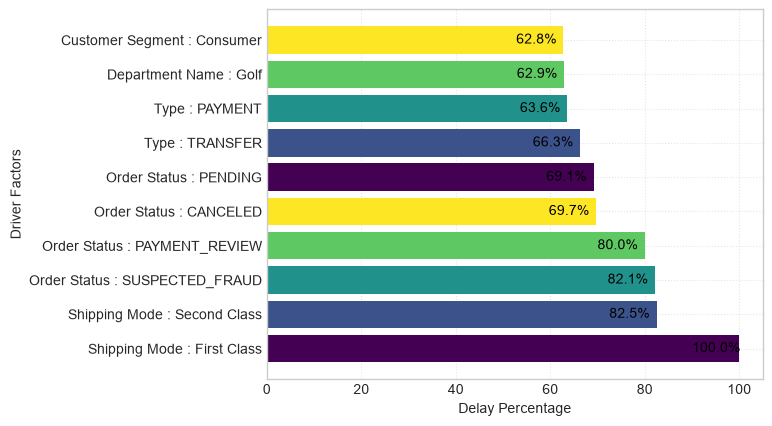

In [19]:
# Root Cause Analysis

def top_deivers_for_region(region):
 df_region=df[df['Order Region']==region].copy()
 drivers=['Shipping Mode','Customer Segment','Department Name','Type','Order Status']

 all_factors=[]

 for factors in drivers:
   temp=(df_region.groupby(factors).agg(
    total_orders=('Delays', 'count'),
    late_orders=('is_delayed', 'sum'),
    avg_delay=('Delays','mean')
 ).reset_index())

   temp['delay_pct']=temp['late_orders']/temp['total_orders']*100
   temp['driver']=factors
   temp['Factor_Level']=factors + " : " + temp[factors].astype(str)

   all_factors.append(temp[['driver','Factor_Level','delay_pct','avg_delay','total_orders']])

  #  combine all drivers
   final_df=pd.concat(all_factors)

  #  Top 10 drivers
 top_factors=final_df.sort_values('delay_pct',ascending=False).head(10)
 plt.figure()

 bars=plt.barh(top_factors['Factor_Level'],top_factors['delay_pct'],color=viridis_colors)
 plt.xlabel('Delay Percentage')
 plt.ylabel('Driver Factors')
 plt.grid(True,linestyle=':',alpha=0.5)
 plt.gca().invert_yaxis
 
 for bar in bars:
    width=bar.get_width()
    plt.text(width -10,bar.get_y()+ bar.get_height()/2 , f'{width:.1f}%', va='center',color='black',fontsize=10)
 plt.show()

top_deivers_for_region('Central Africa')
   

Text(0, 0.5, 'Delay %')

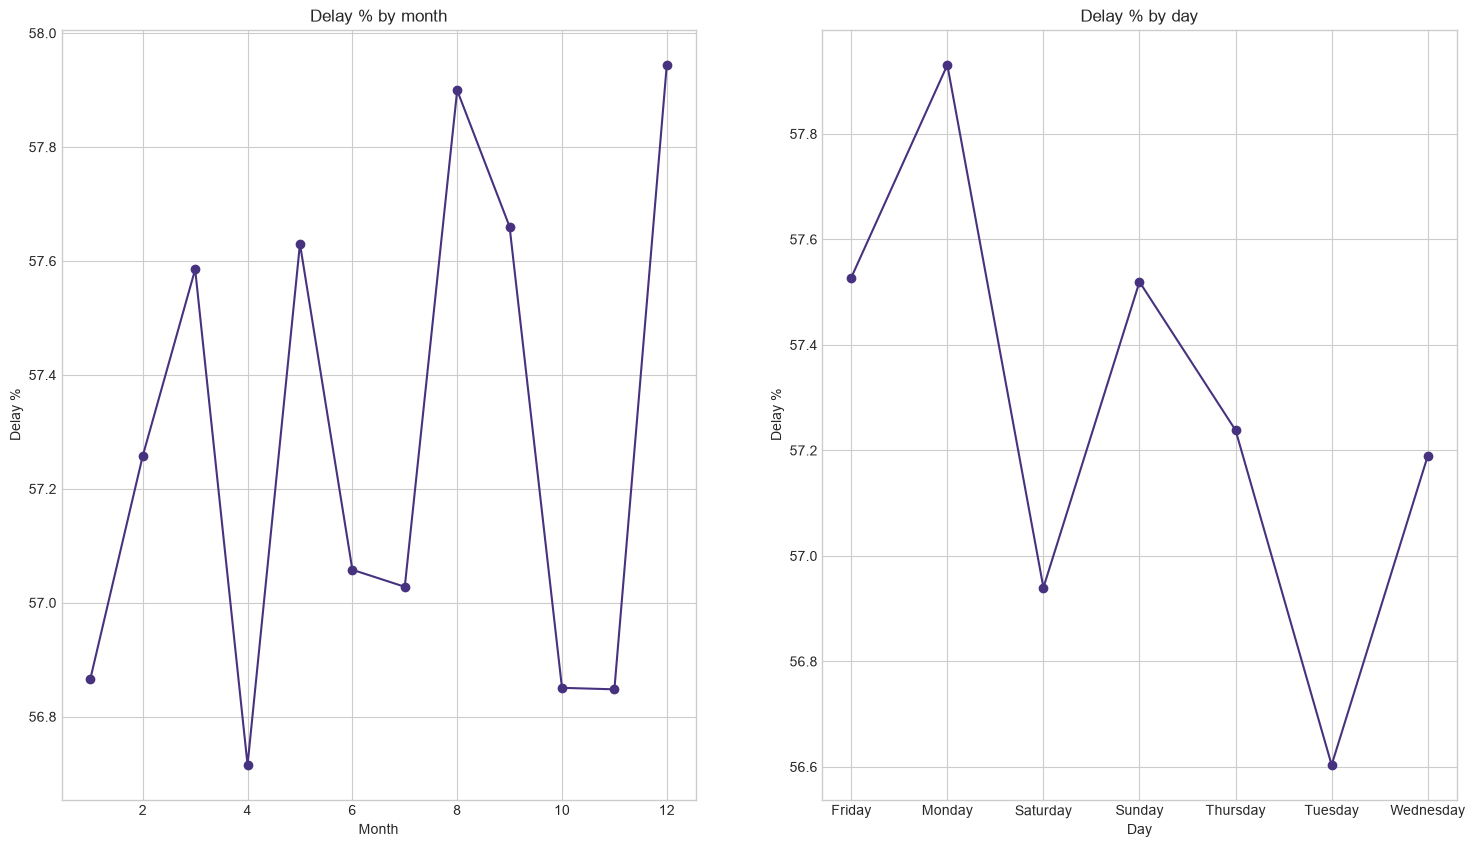

In [20]:
# Time series analysis

month_delay=df.groupby('order_month').agg(
    total_orders=("Delays",'count'),
    late_orders=('is_delayed','sum')
)
month_delay['delay_pct']=(month_delay['late_orders']/month_delay['total_orders'])*100
month_delay.sort_values('delay_pct',ascending=False)

day_delay=df.groupby('order_day').agg(
     total_orders=("Delays",'count'),
        late_orders=('is_delayed','sum')
)
day_delay['delay_pct']=(day_delay['late_orders']/day_delay['total_orders'])*100
day_delay.sort_values('delay_pct',ascending=False)


fig, axes = plt.subplots(1,2,figsize=(18, 10))

axes[0].plot(month_delay.index,month_delay['delay_pct'],marker='o')
axes[0].set_title('Delay % by month')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Delay %')


axes[1].plot(day_delay.index,day_delay['delay_pct'],marker='o')
axes[1].set_title('Delay % by day')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Delay %')
